In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

Διαστάσεις: (1164, 2068)
Min: 0.000
Max: 1.000


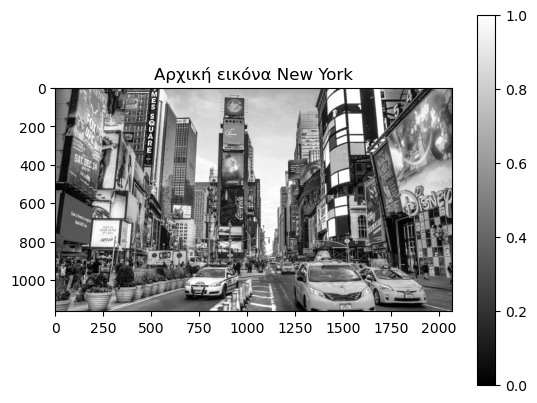

In [2]:
# Φόρτωση εικόνας
img = np.array(Image.open('new_york.png').convert('L'), dtype=float) / 255.0

print(f"Διαστάσεις: {img.shape}")
print(f"Min: {img.min():.3f}")
print(f"Max: {img.max():.3f}")

plt.imshow(img, cmap='gray')
plt.title('Αρχική εικόνα New York')
plt.colorbar()
plt.show()

Ισχύς σήματος: 0.079997
Ισχύς θορύβου: 0.008000


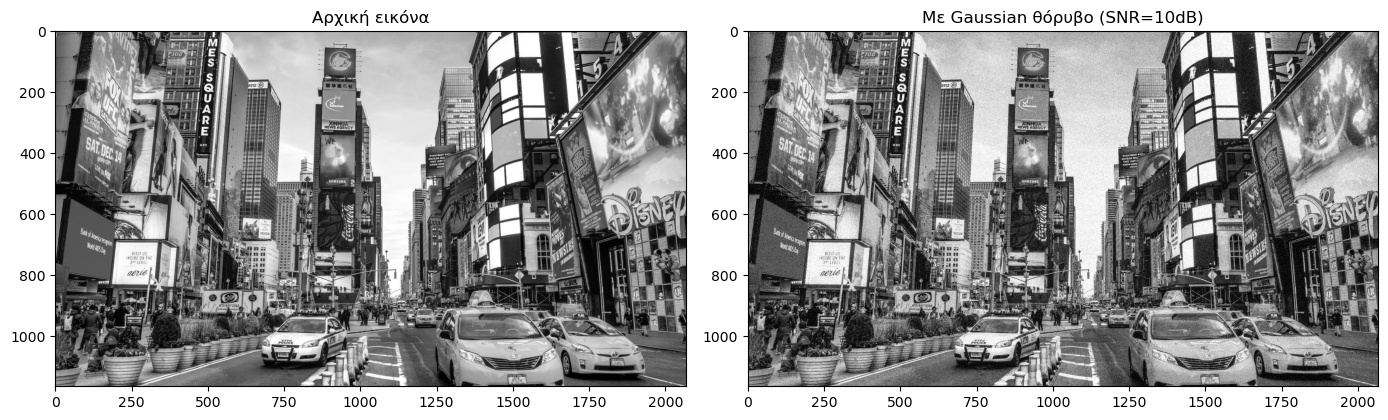

In [3]:
# Υπολογισμός noise power για SNR=10dB
signal_power = np.var(img)
SNR_dB = 10
SNR_linear = 10 ** (SNR_dB / 10)
noise_power = signal_power / SNR_linear

print(f"Ισχύς σήματος: {signal_power:.6f}")
print(f"Ισχύς θορύβου: {noise_power:.6f}")

# Προσθήκη θορύβου
noise = np.random.normal(0, np.sqrt(noise_power), img.shape)
img_noisy = img + noise

# Εμφάνιση
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Αρχική εικόνα')
axes[1].imshow(img_noisy, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Με Gaussian θόρυβο (SNR=10dB)')
plt.tight_layout()
plt.show()

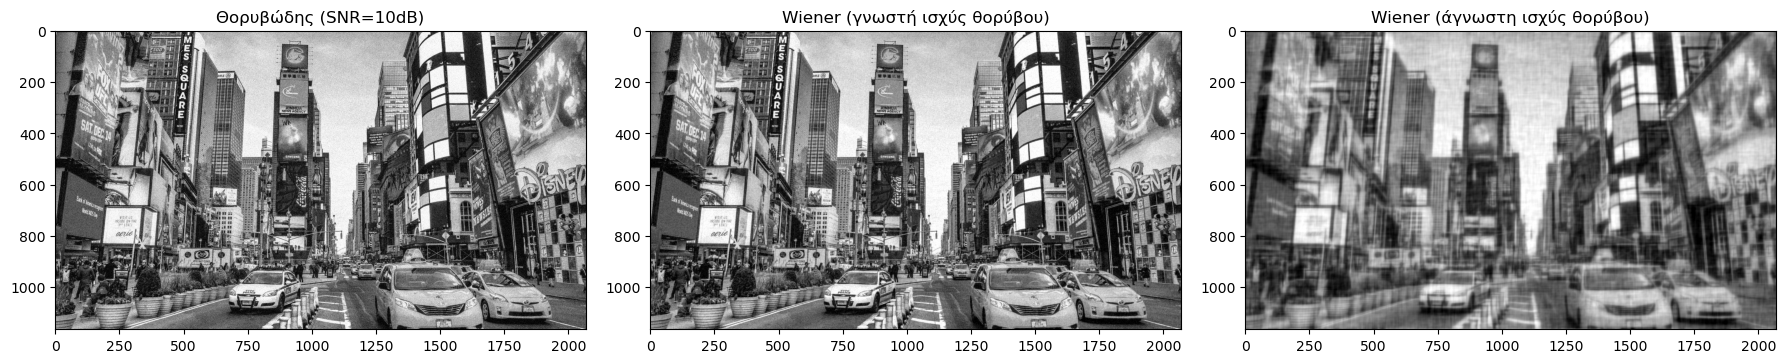

In [4]:
# Wiener filter στο πεδίο συχνοτήτων
F_noisy = np.fft.fft2(img_noisy)
P_signal = np.abs(np.fft.fft2(img))**2  # ισχύς σήματος
P_noise = noise_power * img.size        # ισχύς θορύβου

# Τρόπος 1: γνωρίζουμε την ισχύ θορύβου
H_wiener1 = P_signal / (P_signal + P_noise)
img_wiener1 = np.real(np.fft.ifft2(H_wiener1 * F_noisy))

# Τρόπος 2: εκτιμούμε την ισχύ θορύβου από υψηλές συχνότητες
P_noisy = np.abs(F_noisy)**2
noise_est = np.mean(P_noisy[: , -20:])  # εκτίμηση από άκρες
H_wiener2 = P_noisy / (P_noisy + noise_est)
img_wiener2 = np.real(np.fft.ifft2(H_wiener2 * F_noisy))

# Εμφάνιση
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(img_noisy, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Θορυβώδης (SNR=10dB)')
axes[1].imshow(np.clip(img_wiener1, 0, 1), cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Wiener (γνωστή ισχύς θορύβου)')
axes[2].imshow(np.clip(img_wiener2, 0, 1), cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Wiener (άγνωστη ισχύς θορύβου)')
plt.tight_layout()
plt.show()

Το φίλτρο Wiener λειτουργεί εξαιρετικά όταν γνωρίζουμε την ισχύ του θορύβου. Όταν την εκτιμούμε, το αποτέλεσμα εξαρτάται από την ακρίβεια της εκτίμησης.

Κρουστική απόκριση: Βρέθηκε περνώντας impulse από το σύστημα — είναι ένα μικρό kernel στην πάνω αριστερά γωνία. Η απόκριση συχνότητας δείχνει ελλειπτικό κατωπερατό φίλτρο.
Αντίστροφο φίλτρο με κατώφλι: Το καλύτερο οπτικό αποτέλεσμα επιτεύχθηκε με threshold=0.5. Μικρό threshold = θόρυβος/artifacts, μεγάλο threshold = θόλωμα.
Χωρίς κατώφλι: Το αποτέλεσμα είναι αποδεκτό σε αυτή την περίπτωση γιατί η PSF δεν έχει μηδενικές τιμές — αλλά γενικά χωρίς κατώφλι η διαίρεση με πολύ μικρές τιμές ενισχύει τον θόρυβο καταστροφικά.